<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/200Q_Star_Fluxonium_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# 200-Qubit Star-Fluxonium Chip

Each integer-fluxonium circuit within the 10 × 20 array of native `StarQubit` capacitor electrodes incorporates one aluminium tunnel junction parallel to a granular-aluminium superinductor. Nominal operation at zero applied magnetic flux aligns with the integer-fluxonium regime detailed in [1] alongside the thin-film superinductor approach modeled in [2, 3, 6]. Twenty shared feedlines address ten frequency-separated qubits apiece utilizing native `CoupledLineTee` and `RouteMeander` components bounded by 40 signal launchers distributed across the left and right outer die edges.

## Nomenclature and Symbol Definitions

| Symbol / Acronym | Definition |
| --- | --- |
| **CPW** | Coplanar Waveguide |
| **GDS** | Graphic Data System |
| **SQUID** | Superconducting Quantum Interference Device |
| $\hat{\varphi}$ | Phase operator |
| $\hat n$ | Conjugate charge operator |
| $E_C$ | Charging energy |
| $E_J$ | Josephson energy |
| $E_L$ | Inductive energy |
| $\Phi_0$ | Magnetic flux quantum |
| $h$ | Planck constant |
| $e$ | Elementary charge |
| $L_{\square}$ | Kinetic sheet inductance |
| $\ell$ | Wire length |
| $w$ | Wire width |
| $L_k$ | Kinetic inductance |
| $J_c$ | Junction current density |
| $A_J$ | Junction overlap area |
| $I_c$ | Critical current |
| $v_p$ | Phase velocity |
| $f_r$ | Resonator frequency |

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip X / Y size | Automatically sized; 30 × 26 mm at the supplied settings |
| Qubit array | 10 rows × 20 columns; `Q0` through `Q199` |
| Site pitch X / Y | 1.25 / 2.40 mm |
| Native capacitive geometry | `StarQubit`: radius 80 µm, center radius 27 µm, connector length 20 µm |
| Coupling and readout gaps | 10 µm and 6 µm |
| Qubit circuit | One Josephson junction in parallel with one high-kinetic-inductance wire |
| Nominal operating flux | $\Phi_{\mathrm{ext}}/\Phi_0=0$; no on-chip flux-control lines or SQUID tuners |
| Nominal Josephson and charging energies | $E_J/h=6.78$ GHz; $E_C/h=1.47$ GHz |
| Inductive-energy classes | $E_L/h=0.20,0.21,\ldots,0.29$ GHz |
| Nominal superinductance range | 563.66–817.31 nH |
| Total capacitance target | Approximately 13.18 fF, including junction and coupling contributions |
| Nominal sheet inductance (`SHEET_INDUCTANCE_PH`) | 1000 pH per square |
| High-inductance wire | Width 100 nm, circular fillet radius 1 µm; compact U-shaped shunt |
| Wire length range | Approximately 56–82 µm between contact edges; 4 µm overlap inside each base-metal contact |
| Nominal junction current density (`JUNCTION_CURRENT_DENSITY_A_CM2`) | 50 A/cm² |
| Nominal junction area | Approximately 0.02730 µm²; 200 nm junction width |
| Nominal zero-flux frequency classes | Approximately 3.76–5.33 GHz, calculated from the lumped circuit model |
| Frequency assignment | `(column + 3 * row) % 10`; ten different classes within each feedline group |
| Passive interqubit links | 370 native `RouteStraight` CPW links between capacitive coupling pads |
| CPW conductor width / gap | 8.5 / 5.5 µm |
| Parallel CPW clearance | 200 µm between etched slots, with 225 µm nominal centerline spacing for routing |
| Readout groups | 20 groups containing 10 qubits each |
| Readout targets | Ten equally spaced targets from 6.6 to 8.0 GHz, repeated on independent groups |
| Readout resonators | 200 native `RouteMeander` components with 50 µm circular fillets |
| Resonator leads | 300 µm at the qubit end and 150 µm at the tee end, with two jogs placing the meander in its routing corridor |
| Native meander settings | `spacing=225um`, `asymmetry=-100um`, `prevent_short_edges=true` |
| Readout routing | Tee centers 1.875 mm north and 425 µm east of their stars. Feedline returns use the clearance to set their turns and elevation. |
| Native couplers | `CoupledLineTee`: length 250 µm, spacing option 8 µm, secondary exit length 180 µm, shorted termination |
| Shared microwave access | Qubit-frequency control tones and resonator-frequency readout tones use the same feedline ports |
| Series input capacitors | 20 two-terminal `CapNInterdigital` components directly in the feedline center-conductor paths |
| Signal launchers | 20 on the left edge and 20 on the right edge |
| Minimum launcher pitch | 600 µm center to center |
| Launchpad geometry | Width 170 µm, body length 230 µm, taper 240 µm, lead 25 µm, gap 70 µm |
| Launcher metal inset | 100 µm inside the corresponding outer die edge |
| Ground-bond landing areas | 208 protected areas; 75 µm along the edge × 150 µm inward |
| Ground-bond placement | Three sites between neighboring signal launchers; additional sites along the top and bottom edges |
| Signal crossings | Multilayer airbridges with 110 µm clear spans |
| Ground straps | Native filleted-path sampling at 500 µm pitch, with unsuitable positions rejected |
| GDS layer 1 | Niobium ground, star electrodes, CPWs, launchers, and bridge landings |
| GDS layer 2 | Granular-aluminium high-kinetic-inductance wires |
| GDS layers 3 / 4 | Lower / upper aluminium junction electrodes |
| GDS layer 5 | Aluminium bandage contacts between the island, wire, junction leads, and ground |
| GDS layer 6 | Junction-overlap reference regions |
| GDS layers 7 / 8 / 9 | Airbridge scaffold / elevated metal / contact windows |
| Ground-plane cheesing | Native layer-1 grid: 25 × 25 µm holes on a 100 µm pitch |
| Cheese keep-out (`CHEESE_KEEPOUT`) | Native 25 µm component buffer |
| Cheese edge setting | `edge_nocheese=112.5um`; hole edges lie at least 100 µm inside the die boundary |
| GDS precision | 1 nm |

Here, the phase operator $\hat{\varphi}$ and its conjugate charge operator $\hat n$ dictate the dynamics of the nominal lumped fluxonium system. Electrostatic costs of adding a single Cooper pair to the island are quantified by the charging energy $E_C$. In parallel, the Josephson energy $E_J$ determines the maximum dissipationless tunneling current across the junction. Inductive energy $E_L$ defines the magnetic energy stored in the high-kinetic-inductance shunt. According to quantum mechanics, the ratio of the Planck constant $h$ to the elementary charge $e$ generates the flux quantum $\Phi_0=h/(2e)$ serving as the fundamental scaling unit of magnetic flux. These parameters formulate the Hamiltonian describing the system restricted to the lowest-energy bands.

$$\hat H=4E_C\hat n^2+\frac{E_L}{2}\left(\hat{\varphi}-2\pi\frac{\Phi_{\mathrm{ext}}}{\Phi_0}\right)^2-E_J\cos\hat{\varphi}.$$

The kinetic sheet inductance $L_{\square}$ scales linearly with the geometric ratio of the wire length $\ell$ to the wire width $w$. This scaling yields the nominal shunt inductance $L_k$ in the limit of negligible geometric inductance. Alternatively, the junction current density $J_c$ dictates the required overlap area $A_J$. Such geometric definitions guarantee the target critical current $I_c$.

$$L_k=L_{\square}\frac{\ell}{w}, \qquad E_L=\frac{(\Phi_0/2\pi)^2}{L_k}, \qquad C_{\Sigma}=\frac{e^2}{2E_C}, \qquad I_c=\frac{2\pi E_J}{\Phi_0}, \qquad A_J=\frac{I_c}{J_c}.$$

Evaluating the circuit requires zero external flux alongside two distinct phase grids; this redundancy ensures numerical convergence. Capacitance extraction facilitates the derivation of the charging energy of the drawn star electrodes directly from the physical layout. A thin-film eigenmode solver isolates the wire self-resonances; this derivation bounds the frequency domain validating the lumped element approximation [2, 3]. Material controls enforce nominal input parameters. Measured sheet inductance and junction current density dictate the process-specific wire lengths and overlap areas for physical fabrication.

Each native `RouteMeander` component integrates its circular bends directly into the total path. It is essential that the tee contribution includes the corresponding circular-bend length correction; this geometric inclusion preserves phase coherence. The nominal readout model operates with a phase velocity $v_p=1.20\times10^8$ m/s bounded by a capacitive qubit-facing end and a shorted coupler termination. Frequency-separated microwave tones drive shared control operations within the common readout network. This architecture leverages the resonator-mediated drive mechanism detailed in [4]; the resulting electromagnetic coupling executes single-qubit rotations.

$$\ell_r=\frac{v_p}{4f_r}=\ell_{\mathrm{meander}}+\ell_{\mathrm{coupler}}, \qquad f_r\propto\ell_r^{-1}.$$

## References

1. Mencia, R. A., Lin, W.-J., Cho, H., Vavilov, M. G. and Manucharyan, V. E. (2024) 'Integer fluxonium qubit', *PRX Quantum*, 5, 040318. https://doi.org/10.1103/PRXQuantum.5.040318
2. Grünhaupt, L., Spiecker, M., Gusenkova, D. *et al.* (2019) 'Granular aluminium as a superconducting material for high-impedance quantum circuits', *Nature Materials*, 18, pp. 816–819. https://doi.org/10.1038/s41563-019-0350-3
3. Hazard, T. M., Gyenis, A., Di Paolo, A. *et al.* (2019) 'Nanowire superinductance fluxonium qubit', *Physical Review Letters*, 122, 010504. https://doi.org/10.1103/PhysRevLett.122.010504
4. Blais, A., Grimsmo, A. L., Girvin, S. M. and Wallraff, A. (2021) 'Circuit quantum electrodynamics', *Reviews of Modern Physics*, 93, 025005. https://doi.org/10.1103/RevModPhys.93.025005
5. Huang, S., Lienhard, B., Calusine, G. *et al.* (2021) 'Microwave package design for superconducting quantum processors', *PRX Quantum*, 2, 020306. https://doi.org/10.1103/PRXQuantum.2.020306
6. Janík, M., Roux, K., Borja-Espinosa, C. *et al.* (2025) 'Strong charge-photon coupling in planar germanium enabled by granular aluminium superinductors', *Nature Communications*, 16, 2103. https://doi.org/10.1038/s41467-025-57252-4

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Native star-qubit geometry](https://qiskit-community.github.io/qiskit-metal/catalog/StarQubit.html) · [Native meander routing](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Coupled-line tee options](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html) · [Published crossover-routing helpers](https://github.com/qiskit-community/qiskit-metal/blob/v0.10.1/docs/circuit-examples/F.Small-quantum-chips/resources/wallraff_17q/wallraff_17q.py) · [Native design-rule checks](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.24-Design-rule-checking.html)

In [1]:
!uv pip install -q "quantum-metal==0.10.1" networkx

In [2]:
"""This script builds a 200-site integer-fluxonium layout with star capacitors."""

# --- Control Knobs ---
SHEET_INDUCTANCE_PH = 1000.0
JUNCTION_CURRENT_DENSITY_A_CM2 = 50.0
CHEESE_KEEPOUT = "25um"
OUTPUT_FILENAME = "200_Star_Fluxonium_Qubits.gds"

# --- Imports and Design ---
import logging
import os
import sys
import urllib.request
import warnings
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from scipy.constants import e, h
from scipy.linalg import eigh_tridiagonal
from shapely import STRtree, distance, linestrings, prepare
from qiskit_metal import Dict, designs, draw
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.qubits.star_qubit import StarQubit
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.airbridge import (
    Airbridge,
    _fillet_centerline,
    _placements_along,
)
from qiskit_metal.validation import validate, DEFAULT_RULES, SHAPE_RULES, Waiver
from qiskit_metal.validation.rules import GroundContinuityRule
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

plt.rcParams["figure.dpi"] = 250
qm.logger.setLevel(logging.WARNING)

resources = Path("resources/wallraff_17q_v0_10_1")
resources.mkdir(parents=True, exist_ok=True)
source_url = "https://raw.githubusercontent.com/qiskit-community/qiskit-metal/v0.10.1/docs/circuit-examples/F.Small-quantum-chips/resources/wallraff_17q/"
for filename in ("wallraff_17q.py", "geometry.json"):
    urllib.request.urlretrieve(source_url + filename, resources / filename)
sys.path.insert(0, str(resources.resolve()))
import wallraff_17q as chip

design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
cpw_clearance = float(design.parse_value("200um"))
cpw_gap_mm = float(design.parse_value("5.5um"))
cpw_slot_width = float(design.parse_value("8.5um")) + 2 * cpw_gap_mm
cpw_pitch = cpw_clearance + cpw_slot_width + cpw_gap_mm
qubits, buses, couplers, resonators, launchpads = [], [], [], [], []
physical_records, length_records = [], []
print("Quantum Metal", version("quantum-metal"), flush=True)

Quantum Metal 0.10.1


In [3]:
# --- Zero-Bias Integer-Fluxonium Targets ---
phi0 = h / (2 * e)
ej_ghz, ec_ghz = 6.78, 1.47
el_classes_ghz = np.linspace(0.20, 0.29, 10)
capacitance_target_ff = e**2 / (2 * h * ec_ghz * 1e9) * 1e15
critical_current_na = 2 * np.pi * h * ej_ghz * 1e9 / phi0 * 1e9
junction_area_um2 = (
    critical_current_na * 1e-9 / (JUNCTION_CURRENT_DENSITY_A_CM2 * 1e4) * 1e12
)
inductances_nh = (phi0 / (2 * np.pi)) ** 2 / (h * el_classes_ghz * 1e9) * 1e9
assert SHEET_INDUCTANCE_PH > 0 and JUNCTION_CURRENT_DENSITY_A_CM2 > 0

# Finite-difference spectra use nominal lumped parameters at Phi_ext = 0.
spectrum_records = []
for label, el_ghz in enumerate(el_classes_ghz):
    spectra = []
    for count in (2401, 4801):
        phase = np.linspace(-8 * np.pi, 8 * np.pi, count)
        step = phase[1] - phase[0]
        diagonal = 8 * ec_ghz / step**2 + el_ghz * phase**2 / 2 - ej_ghz * np.cos(phase)
        off_diagonal = np.full(count - 1, -4 * ec_ghz / step**2)
        energies = eigh_tridiagonal(
            diagonal, off_diagonal, select="i", select_range=(0, 4), eigvals_only=True
        )
        spectra.append(energies - energies[0])
    assert np.max(np.abs(spectra[1] - spectra[0])) < 0.003
    spectrum_records.append(
        dict(
            frequency_class=label,
            EJ_GHz=ej_ghz,
            EC_GHz=ec_ghz,
            EL_GHz=el_ghz,
            L_nH=inductances_nh[label],
            C_target_fF=capacitance_target_ff,
            f01_GHz=spectra[1][1],
            f12_GHz=spectra[1][2] - spectra[1][1],
        )
    )
spectrum_table = pd.DataFrame(spectrum_records)
assert np.min(np.diff(spectrum_table.f01_GHz)) > 0.050
display(spectrum_table.round(5))

,frequency_class,EJ_GHz,EC_GHz,EL_GHz,L_nH,C_target_fF,f01_GHz,f12_GHz
0,0,6.78,1.47,0.20,817.30756,13.17703,3.76374,0.00882
1,1,6.78,1.47,0.21,778.38816,13.17703,3.94222,0.00975
2,2,6.78,1.47,0.22,743.00688,13.17703,4.11972,0.01082
3,3,6.78,1.47,0.23,710.70223,13.17703,4.29620,0.01206
4,4,6.78,1.47,0.24,681.08964,13.17703,4.47163,0.01351
5,5,6.78,1.47,0.25,653.84605,13.17703,4.64598,0.01520
6,6,6.78,1.47,0.26,628.69813,13.17703,4.81918,0.01718
7,7,6.78,1.47,0.27,605.41301,13.17703,4.99117,0.01952
8,8,6.78,1.47,0.28,583.79112,13.17703,5.16187,0.02230
9,9,6.78,1.47,0.29,563.66039,13.17703,5.33116,0.02563


In [4]:
# --- Automatic Die Footprint and Native Star Capacitors ---
rows, columns = 10, 20
column_pitch, row_pitch = 1.25, 2.40
readout_height, port_pitch = 1.875, 0.60
chip_x = float(np.ceil(((columns - 1) * column_pitch + 6.0) * 2) / 2)
chip_y = float(
    np.ceil(((rows - 1) * row_pitch + readout_height + port_pitch + 1.9) * 2) / 2
)
design.chips.main.size.size_x = f"{chip_x}mm"
design.chips.main.size.size_y = f"{chip_y}mm"
for row in range(rows):
    for col in range(columns):
        x = (col - (columns - 1) / 2) * column_pitch
        y = (row - (rows - 1) / 2) * row_pitch - (readout_height + port_pitch) / 2
        q = StarQubit(
            design,
            f"Q{row * columns + col}",
            options=Dict(
                pos_x=f"{x}mm",
                pos_y=f"{y}mm",
                radius="80um",
                center_radius="27um",
                gap_couplers="10um",
                gap_readout="6um",
                connector_length="20um",
                trap_offset="6um",
                junc_h="20um",
                cpw_width="8.5um",
                resolution="32",
                number_of_connectors="4",
                rotation_cpl1="90",
                rotation_cpl2="180",
                rotation_cpl3="270",
                rotation_cpl4="0",
                rotation_rdout="135",
                rotation_jj="45",
            ),
        )
        qubits.append(q)
print(
    f"{len(qubits)} star capacitors; automatic footprint {chip_x:g} x {chip_y:g} mm.",
    flush=True,
)

200 star capacitors; automatic footprint 30 x 26 mm.


In [5]:
# --- Single Junctions and Parallel High-Kinetic-Inductance Shunts ---
wire_width, wire_radius = 0.0001, 0.0010
for row in range(rows):
    for col in range(columns):
        q = qubits[row * columns + col]
        center = np.array([float(q.p.pos_x), float(q.p.pos_y)])
        label = (col + 3 * row) % 10
        inductance_nh = inductances_nh[label]
        wire_length = inductance_nh / (SHEET_INDUCTANCE_PH * 1e-3) * wire_width
        drawn_length = wire_length + 0.008
        height = (drawn_length - 0.040 + 2 * (2 - np.pi / 2) * wire_radius) / 2
        assert (
            0.006 < height < 0.030
        ), "Change the compact shunt footprint for this sheet inductance."
        points = np.array([[0.100, 0], [0.100, height], [0.140, height], [0.140, 0]])
        actual_length = (
            np.linalg.norm(np.diff(points, axis=0), axis=1).sum()
            - (len(points) - 2) * (2 - np.pi / 2) * wire_radius
        )
        assert np.isclose(actual_length - 0.008, wire_length, atol=1e-12, rtol=0)

        table = design.qgeometry.tables["poly"]
        island_index = table.index[
            (table.component == q.id) & (table.name == "circle_inner")
        ][0]
        island = table.at[island_index, "geometry"].intersection(
            draw.Point(*center).buffer(0.080, quad_segs=32)
        )
        table.at[island_index, "geometry"] = island
        junctions = design.qgeometry.tables["junction"]
        design.qgeometry.tables["junction"] = junctions[
            junctions.component != q.id
        ].copy()

        tongue = draw.rectangle(0.045, 0.008, 0.0825, 0)
        pocket = draw.rectangle(0.065, 0.072, 0.1125, 0)
        ground_contact = draw.rectangle(0.024, 0.008, 0.148, 0)
        overlap = junction_area_um2 * 1e-6 / 0.0002
        lower = draw.Polygon(
            [
                (0.095, -0.004),
                (0.112, -0.004),
                (0.119, -0.0001),
                (0.120, -0.0001),
                (0.120, 0.0001),
                (0.119, 0.0001),
                (0.112, 0.004),
                (0.095, 0.004),
            ]
        )
        upper = draw.Polygon(
            [
                (0.120 - overlap, -0.0001),
                (0.121, -0.0001),
                (0.128, -0.004),
                (0.145, -0.004),
                (0.145, 0.004),
                (0.128, 0.004),
                (0.121, 0.0001),
                (0.120 - overlap, 0.0001),
            ]
        )
        bandages = draw.union(
            draw.rectangle(0.006, 0.006, 0.100, 0),
            draw.rectangle(0.006, 0.006, 0.140, 0),
        )
        overlap_mask = draw.rectangle(overlap, 0.0002, 0.120 - overlap / 2, 0)
        junction = draw.LineString([(0.120 - overlap, 0), (0.120, 0)])
        lower = draw.union(
            draw.translate(lower, yoff=-0.020),
            draw.rectangle(0.008, 0.028, 0.100, -0.010),
        )
        upper = draw.union(
            draw.translate(upper, yoff=-0.020),
            draw.rectangle(0.008, 0.028, 0.140, -0.010),
        )
        overlap_mask, junction = draw.translate([overlap_mask, junction], yoff=-0.020)
        wire = draw.LineString(points)
        (
            tongue,
            pocket,
            ground_contact,
            lower,
            upper,
            bandages,
            overlap_mask,
            junction,
            wire,
        ) = draw.translate(
            draw.rotate(
                [
                    tongue,
                    pocket,
                    ground_contact,
                    lower,
                    upper,
                    bandages,
                    overlap_mask,
                    junction,
                    wire,
                ],
                315,
                origin=(0, 0),
            ),
            *center
        )
        assert island.intersection(tongue).area > 1e-5, q.name
        q.add_qgeometry("poly", {"inductor_pocket": pocket}, subtract=True, layer=1)
        q.add_qgeometry("poly", {"island_contact": tongue}, layer=1)
        q.add_qgeometry("poly", {"ground_contact": ground_contact}, layer=1)
        q.add_qgeometry(
            "path",
            {"high_Lk_shunt": wire},
            width=wire_width,
            fillet=wire_radius,
            layer=2,
        )
        q.add_qgeometry("poly", {"junction_lower": lower}, layer=3)
        q.add_qgeometry("poly", {"junction_upper": upper}, layer=4)
        q.add_qgeometry("poly", {"bandage_contacts": bandages}, layer=5)
        q.add_qgeometry("poly", {"junction_overlap": overlap_mask}, layer=6)
        q.add_qgeometry("junction", {"JJ": junction}, width=0.0002, layer=3)
        physical_records.append(
            dict(
                qubit=q.name,
                row=row,
                column=col,
                frequency_class=label,
                L_nH=inductance_nh,
                wire_length_um=wire_length * 1000,
                nominal_junction_area_um2=junction_area_um2,
                drawn_wire_length_um=drawn_length * 1000,
                model_f01_GHz=float(spectrum_table.iloc[label].f01_GHz),
            )
        )
print("Single-junction fluxonium loops", len(physical_records), flush=True)

Single-junction fluxonium loops 200


In [6]:
# --- Passive Nearest-Neighbor CPW Links ---
for row in range(rows):
    for col in range(columns):
        a = qubits[row * columns + col]
        neighbors = []
        if col + 1 < columns:
            neighbors.append((qubits[row * columns + col + 1], "pin_cpl1", "pin_cpl3"))
        if row + 1 < rows:
            neighbors.append(
                (qubits[(row + 1) * columns + col], "pin_cpl2", "pin_cpl4")
            )
        for b, start_pin, end_pin in neighbors:
            buses.append(
                RouteStraight(
                    design,
                    f"BUS_{a.name}_{b.name}",
                    options=Dict(
                        trace_width="8.5um",
                        trace_gap="5.5um",
                        pin_inputs=Dict(
                            start_pin=Dict(component=a.name, pin=start_pin),
                            end_pin=Dict(component=b.name, pin=end_pin),
                        ),
                    ),
                )
            )

# --- Multiplexed Readout and Microwave Access ---
readout_frequencies = np.linspace(6.6, 8.0, 10)
phase_velocity = 1.20e8
for row in range(rows):
    for col in range(columns):
        index = row * columns + col
        q = qubits[index]
        x, y = float(q.p.pos_x), float(q.p.pos_y)
        tee = CoupledLineTee(
            design,
            f"CLT{index}",
            options=Dict(
                pos_x=f"{x + 0.425}mm",
                pos_y=f"{y + readout_height}mm",
                prime_width="8.5um",
                prime_gap="5.5um",
                second_width="8.5um",
                second_gap="5.5um",
                coupling_length="250um",
                coupling_space="8um",
                down_length="180um",
                fillet="50um",
                open_termination=False,
            ),
        )
        secondary = tee.qgeometry_table("path").query("name == 'second_cpw'").iloc[0]
        arm_length = secondary.geometry.length - (2 - np.pi / 2) * secondary.fillet
        target_length = phase_velocity / (4 * readout_frequencies[col % 10] * 1e9) * 1e3
        route = RouteMeander(
            design,
            f"RO_{index}",
            options=Dict(
                trace_width="8.5um",
                trace_gap="5.5um",
                fillet="50um",
                total_length=f"{target_length - arm_length}mm",
                pin_inputs=Dict(
                    start_pin=Dict(component=q.name, pin="pin_rdout"),
                    end_pin=Dict(component=tee.name, pin="second_end"),
                ),
                lead=Dict(
                    start_straight="300um",
                    end_straight="150um",
                    start_jogged_extension=Dict(
                        {0: ["R45", "300um"], 1: ["L90", f"{cpw_pitch:g}mm"]}
                    ),
                ),
                meander=Dict(spacing=f"{cpw_pitch:g}mm", asymmetry="-100um"),
                prevent_short_edges="true",
            ),
        )
        couplers.append(tee)
        resonators.append(route)
        length_records.append(
            dict(
                qubit=q.name,
                target_GHz=readout_frequencies[col % 10],
                length_mm=route.length + arm_length,
            )
        )
print(
    len(buses),
    "passive links;",
    len(resonators),
    "coupled readout resonators.",
    flush=True,
)

370 passive links; 200 coupled readout resonators.


In [7]:
# --- Feedline Groups and Edge Launchpads ---
feedline_connections = []
feed_fillet = float(design.parse_value("35um"))
for row in range(rows):
    y = float(qubits[row * columns].p.pos_y) + readout_height
    for half, side in enumerate((-1, 1)):
        indices = list(
            range(row * columns + half * 10, row * columns + (half + 1) * 10)
        )
        if side == 1:
            indices.reverse()
        entry, exit = (
            ("prime_start", "prime_end") if side == -1 else ("prime_end", "prime_start")
        )
        tag = f"{row}_{half}"
        group = [couplers[i] for i in indices]
        cap = CapNInterdigital(
            design,
            f"CAP_{tag}",
            options=Dict(
                pos_x=f"{side*(chip_x/2-1.1)}mm",
                pos_y=f"{y}mm",
                orientation=str(side * 90),
                north_width="8.5um",
                north_gap="5.5um",
                south_width="8.5um",
                south_gap="5.5um",
                cap_width="10um",
                cap_gap="6um",
                cap_gap_ground="6um",
                finger_length="20um",
                finger_count="5",
                cap_distance="50um",
            ),
        )
        for label, py in (("IN", y), ("OUT", y + port_pitch)):
            pad = LaunchpadWirebond(
                design,
                f"LP_FEED_{tag}_{label}",
                options=Dict(
                    pos_x=f"{side*(chip_x/2-.570)}mm",
                    pos_y=f"{py}mm",
                    orientation="0" if side == -1 else "180",
                    trace_width="8.5um",
                    trace_gap="5.5um",
                    lead_length="25um",
                    pad_width="170um",
                    pad_height="230um",
                    taper_height="240um",
                    pad_gap="70um",
                ),
            )
            launchpads.append(pad)
            if label == "IN":
                a, b, ap, bp = pad, cap, "tie", "south_end"
                pts = [a.pins[ap].middle, b.pins[bp].middle]
            else:
                a, b, ap, bp = group[-1], pad, exit, "tie"
                p0 = np.asarray(a.pins[ap].middle)
                p1 = np.asarray(b.pins[bp].middle)
                qx = float(qubits[indices[-1]].p.pos_x)
                if side > 0:
                    turn_x = qx - cpw_pitch
                else:
                    turn_x = p0[0] + 2 * feed_fillet + cpw_slot_width + cpw_gap_mm
                return_y = min(py, y + row_pitch - readout_height - cpw_pitch)
                pts = [p0, [turn_x, y], [turn_x, return_y]]
                if return_y < py:
                    lead_x = p1[0] - side * 0.100
                    diagonal_run = max(0.150, py - return_y)
                    pts.extend(
                        [[lead_x - side * diagonal_run, return_y], [lead_x, py]]
                    )
                pts.append(p1)
            feedline_connections.append((f"FEED_{tag}_{label}", a, ap, b, bp, pts))
        joints = [(cap, "north_end", group[0], entry)]
        joints += [(a, exit, b, entry) for a, b in zip(group[:-1], group[1:])]
        for k, (a, ap, b, bp) in enumerate(joints):
            pts = [a.pins[ap].middle, b.pins[bp].middle]
            feedline_connections.append((f"FEED_{tag}_{k}", a, ap, b, bp, pts))

bus_names = {bus.id: bus.name for bus in buses}
paths = design.qgeometry.tables["path"]
bus_paths = paths[paths.component.isin(bus_names) & ~paths["subtract"]]
bus_tree = STRtree(bus_paths.geometry.to_list())
for name, a, ap, b, bp, pts in feedline_connections:
    hits = bus_tree.query(draw.LineString(pts), predicate="intersects")
    crossed_buses = tuple(bus_names[cid] for cid in bus_paths.iloc[hits].component)
    items = chip.split_at_crossings(design, pts, name, over=crossed_buses, tag="ABF")
    chain, part = [], 0
    for kind, geometry in items:
        if kind == "bridge":
            chain.append((design.components[geometry], "a", "b"))
        else:
            route = chip.PolylineCPW(
                design,
                name + (f"_{part}" if part else ""),
                options=Dict(
                    points=[list(map(float, point)) for point in geometry],
                    trace_width="8.5um",
                    trace_gap="5.5um",
                    fillet=f"{feed_fillet:g}mm",
                ),
            )
            chain.append((route, "start", "end"))
            part += 1
    for left, right in zip(chain[:-1], chain[1:]):
        design.connect_pins(left[0].id, left[2], right[0].id, right[1])
    design.connect_pins(a.id, ap, chain[0][0].id, chain[0][1])
    design.connect_pins(chain[-1][0].id, chain[-1][2], b.id, bp)
print("Readout launchers", len(launchpads), flush=True)


Readout launchers 40


In [8]:
# --- Parallel CPW Clearance ---
slot_paths = design.qgeometry.tables["path"].query("subtract and layer == 1")
straight_runs, run_widths, run_paths, run_owners = [], [], [], []
for path_id, path in enumerate(slot_paths.itertuples()):
    points = np.asarray(path.geometry.simplify(1e-10).coords)
    steps = np.diff(points, axis=0)
    lengths = np.linalg.norm(steps, axis=1)
    directions = steps / lengths[:, None]
    turn_angles = np.arccos(
        np.clip(np.sum(directions[1:] * directions[:-1], axis=1), -1, 1)
    )
    trim = np.minimum(
        path.fillet * np.tan(turn_angles / 2),
        np.minimum(lengths[:-1], lengths[1:]) / 2,
    )
    starts = points[:-1] + np.r_[0, trim][:, None] * directions
    stops = points[1:] - np.r_[trim, 0][:, None] * directions
    for start, stop in zip(starts, stops):
        if np.linalg.norm(stop - start) > 1e-6:
            straight_runs.append([start, stop])
            run_widths.append(path.width)
            run_paths.append(path_id)
            run_owners.append(path.component)

runs = np.asarray(straight_runs)
paths = linestrings(runs)
widths = np.asarray(run_widths)
owners = np.asarray(run_owners)
path_ids = np.asarray(run_paths)
tee_ids = [tee.id for tee in couplers]
left, right = STRtree(paths).query(paths, predicate="dwithin", distance=2 * cpw_pitch)
same_tee_pair = (
    (owners[left] == owners[right])
    & (path_ids[left] != path_ids[right])
    & np.isin(owners[left], tee_ids)
)
keep = (left < right) & ~same_tee_pair
left, right = left[keep], right[keep]
steps = runs[:, 1] - runs[:, 0]
lengths = np.linalg.norm(steps, axis=1)
directions = steps / lengths[:, None]
parallel = (
    abs(np.sum(directions[left] * directions[right], axis=1)) >= np.cos(np.deg2rad(3))
)
left, right = left[parallel], right[parallel]
projection = np.einsum("ijk,ik->ij", runs[right] - runs[left, :1], directions[left])
overlap = np.minimum(lengths[left], projection.max(axis=1)) - np.maximum(
    0, projection.min(axis=1)
)
left, right = left[overlap > 1e-6], right[overlap > 1e-6]
spacing = distance(paths[left], paths[right]) - (widths[left] + widths[right]) / 2
if len(spacing):
    closest = int(np.argmin(spacing))
    pair = [design._components[int(owners[i])].name for i in (left[closest], right[closest])]
    print(
        f"Minimum unintended parallel CPW gap: {1000 * spacing[closest]:.1f} µm "
        f"({pair[0]} and {pair[1]}).",
        flush=True,
    )
    assert spacing[closest] >= cpw_clearance - 1e-6, (pair, spacing[closest])

Minimum unintended parallel CPW gap: 205.5 µm (BUS_Q67_Q68 and FEED_2_0_OUT_2).


In [9]:
# --- Multilayer Signal Crossovers ---
crossings = [c for c in design.components.values() if c.name.startswith("XO_")]
for old in list(design.components.values()):
    if not isinstance(old, Airbridge):
        continue
    name = "XO_" + old.name
    cx, cy = float(old.p.pos_x), float(old.p.pos_y)
    angle = float(old.p.orientation)
    length = float(old.p.crossover_length)
    feet_center = length / 2 + 0.0055
    peers = []
    for pin_name in ("a", "b"):
        net_id = old.pins[pin_name].net_id
        match = design.net_info[
            (design.net_info.net_id == net_id)
            & (design.net_info.component_id != old.id)
        ]
        for _, peer in match.iterrows():
            peers.append(
                (
                    pin_name,
                    design._components[int(peer.component_id)].name,
                    peer.pin_name,
                )
            )
    pin_points = {p: old.pins[p].points.copy() for p in ("a", "b")}
    design.delete_component(old.name)
    crossing = QComponent(
        design,
        name,
        options=Dict(
            pos_x=f"{cx}mm", pos_y=f"{cy}mm", orientation=str(angle), layer="1"
        ),
        make=False,
    )
    feet = draw.union(
        draw.rectangle(0.011, 0.011, -feet_center, 0),
        draw.rectangle(0.011, 0.011, feet_center, 0),
    )
    clearance = draw.union(
        draw.rectangle(0.022, 0.022, -feet_center, 0),
        draw.rectangle(0.022, 0.022, feet_center, 0),
    )
    span = draw.rectangle(2 * (feet_center + 0.005), 0.0085)
    scaffold = draw.rectangle(length + 0.001, 0.0195)
    contacts = draw.union(
        draw.rectangle(0.006, 0.005, -feet_center, 0),
        draw.rectangle(0.006, 0.005, feet_center, 0),
    )
    objects = draw.translate(
        draw.rotate([feet, clearance, span, scaffold, contacts], angle, origin=(0, 0)),
        cx,
        cy,
    )
    feet, clearance, span, scaffold, contacts = objects
    crossing.add_qgeometry("poly", {"base_landings": feet}, layer=1)
    crossing.add_qgeometry(
        "poly", {"landing_clearance": clearance}, layer=1, subtract=True
    )
    crossing.add_qgeometry("poly", {"reflow_scaffold": scaffold}, layer=7)
    crossing.add_qgeometry("poly", {"AlTiAl_overpass": span}, layer=8)
    crossing.add_qgeometry("poly", {"contacts": contacts}, layer=9)
    for p in ("a", "b"):
        middle = np.asarray(pin_points[p]).mean(axis=0)
        peer_name, peer_pin = next((n, pn) for pin, n, pn in peers if pin == p)
        route = design.components[peer_name]
        trace = route.qgeometry_table("path")
        if trace.empty:
            crossing.add_pin(p, np.asarray(pin_points[p]), width=0.011)
            continue
        coords = np.asarray(trace[~trace["subtract"]].iloc[0].geometry.coords)
        if np.linalg.norm(coords[-1] - middle) < np.linalg.norm(coords[0] - middle):
            coords = coords[::-1]
        normal = coords[1] - coords[0]
        normal /= np.linalg.norm(normal)
        crossing.add_pin(
            p,
            np.array([middle - 0.01 * normal, middle]),
            width=0.011,
            input_as_norm=True,
        )
    for p, peer_name, peer_pin in peers:
        design.connect_pins(crossing.id, p, design.components[peer_name].id, peer_pin)
    crossings.append(crossing)
print("PROCESS CROSSOVERS", len(crossings), flush=True)

PROCESS CROSSOVERS 360


In [10]:
# --- Perimeter Ground-Bond Landing Areas ---
port_records = []
for pad in launchpads:
    edge = "left" if float(pad.p.pos_x) < 0 else "right"
    port_records.append(
        dict(
            component=pad.name,
            edge=edge,
            x_mm=float(pad.p.pos_x),
            y_mm=float(pad.p.pos_y),
        )
    )
port_table = pd.DataFrame(port_records)
ground_sheet = GroundContinuityRule(chip="main", layer=1)._ground_sheet(
    design, chip="main"
)
bond_lands, bond_records = {}, []
for edge, bank in port_table.groupby("edge"):
    positions = np.sort(bank.y_mm.to_numpy())
    assert len(bank) == 20
    assert np.min(np.diff(positions)) >= port_pitch - 1e-9
    for gap, middle in enumerate((positions[:-1] + positions[1:]) / 2):
        for site, offset in enumerate((-0.100, 0.000, 0.100)):
            x = (-1 if edge == "left" else 1) * (chip_x / 2 - 0.250)
            y = middle + offset
            landing = draw.rectangle(0.150, 0.075, x, y)
            assert ground_sheet.covers(landing.buffer(0.005)), (edge, gap, site)
            name = f"GND_{edge}_{gap}_{site}"
            bond_lands[name] = landing
            bond_records.append(
                dict(component=name, edge=edge, x_mm=x, y_mm=y, net="ground")
            )
count = int((chip_x - 2.0) / port_pitch) + 1
positions = (np.arange(count) - (count - 1) / 2) * port_pitch
for edge, side in (("bottom", -1), ("top", 1)):
    for site, x in enumerate(positions):
        y = side * (chip_y / 2 - 0.250)
        landing = draw.rectangle(0.075, 0.150, x, y)
        assert ground_sheet.covers(landing.buffer(0.005)), (edge, site)
        name = f"GND_{edge}_{site}"
        bond_lands[name] = landing
        bond_records.append(
            dict(component=name, edge=edge, x_mm=x, y_mm=y, net="ground")
        )
ground_bond_component = QComponent(design, "GroundBondLands", make=False)
ground_bond_component.add_qgeometry("poly", bond_lands, layer=1)
ground_bond_table = pd.DataFrame(bond_records)
print(
    len(launchpads),
    "signal launchers;",
    len(bond_lands),
    "protected ground-bond sites.",
    flush=True,
)

40 signal launchers; 208 protected ground-bond sites.


In [11]:
# --- Ground Straps Along the Filleted CPWs ---
if "GroundStraps" in design.components:
    design.delete_component("GroundStraps")

from shapely import STRtree, prepare
from qiskit_metal.qlibrary.tlines.airbridge import _fillet_centerline, _placements_along

ground_sheet = GroundContinuityRule(chip="main", layer=1)._ground_sheet(
    design, chip="main"
)
ground_regions = [
    p for p in getattr(ground_sheet, "geoms", [ground_sheet]) if p.area > 1e-4
]
ground_graph = nx.Graph()
ground_graph.add_nodes_from(range(len(ground_regions)))
safe_regions = [region.buffer(-0.001) for region in ground_regions]
prepare(safe_regions)
region_tree = STRtree(safe_regions)
bridge_spans = [
    c.qgeometry_table("poly").query("subtract == False").geometry.union_all()
    for c in crossings
]
span_tree = STRtree(bridge_spans)
pending_spans = []
ground_straps = []
ground_masks = {layer: {} for layer in (1, 7, 8, 9)}
strap_pitch = float(design.parse_value("500um"))
for route in list(design.components.values()):
    if not isinstance(route, (chip.PolylineCPW, RouteStraight, RouteMeander)):
        continue
    paths = route.qgeometry_table("path")
    points = np.asarray(paths[~paths["subtract"]].iloc[0].geometry.coords)
    steps = np.diff(points, axis=0)
    turns = steps[:-1, 0] * steps[1:, 1] - steps[:-1, 1] * steps[1:, 0]
    points = points[np.r_[True, np.abs(turns) > 1e-12, True]]
    radius = float(design.parse_value(route.options.get("fillet", "0um")))
    rounded = _fillet_centerline(points, radius)
    placements = _placements_along(rounded, strap_pitch, 0.100)
    for index, (cx, cy, angle) in enumerate(placements):
        feet_center = 0.0305
        feet = [draw.rectangle(0.011, 0.011, side * feet_center, 0) for side in (-1, 1)]
        span = draw.rectangle(0.071, 0.0085)
        scaffold = draw.rectangle(0.051, 0.0195)
        contacts = draw.union(
            *[draw.rectangle(0.006, 0.005, side * feet_center, 0) for side in (-1, 1)]
        )
        feet = draw.translate(draw.rotate(feet, angle, origin=(0, 0)), cx, cy)
        span, scaffold, contacts = draw.translate(
            draw.rotate([span, scaffold, contacts], angle, origin=(0, 0)), cx, cy
        )
        regions = []
        for foot in feet:
            matches = [
                int(i) for i in region_tree.query(foot) if safe_regions[i].covers(foot)
            ]
            if matches:
                regions.append(matches[0])
        if len(regions) != 2:
            continue
        envelope = draw.union(span, scaffold, *feet)
        if len(span_tree.query(envelope, predicate="dwithin", distance=0.003)):
            continue
        if any(envelope.distance(other) < 0.003 for other in pending_spans):
            continue
        name = f"GS_{route.name}_{index}"
        for layer, geometry in (
            (1, draw.union(*feet)),
            (7, scaffold),
            (8, span),
            (9, contacts),
        ):
            ground_masks[layer][name] = geometry
        ground_straps.append(name)
        ground_graph.add_edge(*regions)
        bridge_spans.append(envelope)
        pending_spans.append(envelope)
        if len(pending_spans) >= 32:
            span_tree = STRtree(bridge_spans)
            pending_spans.clear()
assert nx.is_connected(ground_graph), list(nx.connected_components(ground_graph))
ground_component = QComponent(design, "GroundStraps", make=False)
for layer, geometries in ground_masks.items():
    ground_component.add_qgeometry("poly", geometries, layer=layer)
print(
    f"{len(ground_straps)} ground straps connect all {len(ground_regions)} Nb ground regions."
)

3430 ground straps connect all 172 Nb ground regions.


In [12]:
# --- Native Routing, Geometry, and Circuit Checks ---
assert len(qubits) == 200 and len(buses) == 370
assert len(couplers) == len(resonators) == 200 and len(launchpads) == 40
assert len(design.qgeometry.tables["junction"]) == 200
assert not any(name.startswith(("FLUX_", "SQUID_")) for name in design.components)
assert nx.is_connected(ground_graph)
for table_name in ("poly", "path", "junction"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
    xmin, ymin, xmax, ymax = table.geometry.total_bounds
    assert xmin >= -chip_x / 2 and xmax <= chip_x / 2, table_name
    assert ymin >= -chip_y / 2 and ymax <= chip_y / 2, table_name
for pad in launchpads:
    metal = pad.qgeometry_table("poly").query("subtract == False").geometry.union_all()
    xmin, ymin, xmax, ymax = metal.bounds
    assert np.isclose(
        min(xmin + chip_x / 2, chip_x / 2 - xmax), 0.100, atol=1e-6
    ), pad.name
for q in qubits:
    table = q.qgeometry_table("poly")
    base = table[(table.layer == 1) & ~table["subtract"]].geometry.union_all()
    bandages = table[table.layer == 5].geometry.union_all()
    lower = table[table.layer == 3].geometry.union_all()
    upper = table[table.layer == 4].geometry.union_all()
    overlaps = table[table.layer == 6].geometry.union_all()
    island_contact = table[
        table.name.isin(("circle_inner", "island_contact"))
    ].geometry.union_all()
    ground_contact = table[table.name == "ground_contact"].geometry.union_all()
    assert ground_contact.intersection(ground_sheet).area > 1e-5, q.name
    assert island_contact.distance(ground_contact) > 0.010, q.name
    for pad in table[table.name.str.startswith("contact_")].geometry:
        assert island_contact.distance(pad) >= 0.005, q.name
    assert np.isclose(
        lower.intersection(upper).area, overlaps.area, atol=1e-15, rtol=1e-4
    ), q.name
    for bandage in bandages.geoms:
        assert base.covers(bandage) or ground_sheet.covers(bandage), q.name
        assert lower.union(upper).buffer(1e-9).covers(bandage), q.name
    wire = q.qgeometry_table("path").query("name == 'high_Lk_shunt'").iloc[0]
    rounded = draw.LineString(
        _fillet_centerline(np.asarray(wire.geometry.coords), wire.fillet)
    )
    assert rounded.is_simple, q.name
    contact_neighborhoods = draw.union(
        *[draw.Point(*p).buffer(0.006) for p in (rounded.coords[0], rounded.coords[-1])]
    )
    unexpected_contact = (
        rounded.buffer(wire_width / 2)
        .intersection(lower.union(upper))
        .difference(contact_neighborhoods)
    )
    assert unexpected_contact.area < 1e-12, q.name
    for endpoint in (rounded.coords[0], rounded.coords[-1]):
        assert bandages.covers(draw.Point(*endpoint)), q.name
for component in crossings + [ground_component]:
    table = component.qgeometry_table("poly")
    lower = table[(table.layer == 1) & ~table["subtract"]].geometry.union_all()
    upper = table[table.layer == 8].geometry.union_all()
    contacts = table[table.layer == 9].geometry.union_all()
    assert lower.buffer(1e-9).covers(contacts), component.name
    assert upper.buffer(1e-9).covers(contacts), component.name
for route in resonators:
    distances = np.linalg.norm(np.diff(route.get_points(), axis=0), axis=1)
    radius = float(route.p.fillet)
    assert np.min(distances[[0, -1]]) >= radius - 1e-9, route.name
    assert np.min(distances[1:-1]) >= 2 * radius - 1e-9, route.name
length_table = pd.DataFrame(length_records)
length_table["model_GHz"] = phase_velocity / (4 * length_table.length_mm * 1e-3) / 1e9
assert np.max(np.abs(length_table.model_GHz - length_table.target_GHz)) < 1e-5
physical_table = pd.DataFrame(physical_records)
for row in range(rows):
    for half in range(2):
        bank = physical_table[
            (physical_table.row == row) & (physical_table.column // 10 == half)
        ]
        assert len(bank.frequency_class.unique()) == 10
        assert np.min(np.diff(np.sort(bank.model_f01_GHz))) > 0.050

waivers = [
    Waiver(
        rule="ground-continuity",
        reason=f"The verified elevated-strap graph connects all {len(ground_regions)} base-ground regions; the native rule sees layer 1 only.",
    )
]
drc = validate(design, rules=[*DEFAULT_RULES, *SHAPE_RULES], waivers=waivers)
print(drc.report())
drc.raise_if_errors()
summary = pd.DataFrame(
    [
        ("Star fluxonium sites / single junctions", 200),
        ("Flux-bias lines", 0),
        ("Passive nearest-neighbor CPW links", len(buses)),
        ("Coupled readout resonators", len(resonators)),
        ("Shared readout/control feedlines", 20),
        ("Perimeter signal launchers", len(launchpads)),
        ("Signal crossings", len(crossings)),
        ("Ground straps", len(ground_straps)),
        ("Ground-bond landing sites", len(bond_lands)),
        ("Chip X / Y (mm)", f"{chip_x:g} / {chip_y:g}"),
    ],
    columns=["Layout item", "Count or size"],
)
display(summary)
display(port_table.groupby("edge").size().rename("Signal ports").to_frame())
display(length_table.round(6))

Design rules passed (12 rules ran, no findings).
1 waived:
  [warning] ground-continuity: ground plane on layer 1 is split into 172 disconnected regions (mm^2: 254.498, 2.778, 2.778, 2.778, ...); confirm airbridges or vias tie them together -- this check sees only same-layer metal  @ (-11.3850, -5.9422)
      waived: The verified elevated-strap graph connects all 172 base-ground regions; the native rule sees layer 1 only.


,Layout item,Count or size
0,Star fluxonium sites / single junctions,200
1,Flux-bias lines,0
2,Passive nearest-neighbor CPW links,370
3,Coupled readout resonators,200
4,Shared readout/control feedlines,20
5,Perimeter signal launchers,40
6,Signal crossings,360
7,Ground straps,3430
8,Ground-bond landing sites,208
9,Chip X / Y (mm),30 / 26


,Signal ports
edge,
left,20
right,20


,qubit,target_GHz,length_mm,model_GHz
0,Q0,6.600000,4.545455,6.600000
1,Q1,6.755556,4.440789,6.755556
2,Q2,6.911111,4.340836,6.911111
3,Q3,7.066667,4.245283,7.066667
4,Q4,7.222222,4.153846,7.222222
...,...,...,...,...
195,Q195,7.377778,4.066265,7.377778
196,Q196,7.533333,3.982301,7.533333
197,Q197,7.688889,3.901734,7.688889
198,Q198,7.844444,3.824363,7.844444


In [13]:
# --- Native Cheesing and GDSII Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds = QGDSRenderer(design, initiate=False)
gds.options.precision = "1e-9"
gds.options.tolerance = "1e-6"
gds.options.max_points = "8190"
gds.options.fabricate = "True"
gds.options.short_segments_to_not_fillet = "False"
gds.options.path_filename = None
gds.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds.options.cheese.edge_nocheese = "112.5um"
gds.options.no_cheese.buffer = CHEESE_KEEPOUT
gds.options.cheese.view_in_file = Dict(
    main={layer: layer == 1 for layer in range(1, 10)}
)
gds.options.no_cheese.view_in_file = Dict(main={layer: False for layer in range(1, 10)})

# Physical junction electrodes already occupy layers 3 and 4.
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=RuntimeWarning,
            message=r"^Error in boolean operation\.$",
            module=r"^qiskit_metal\.renderers\.renderer_gds\.gds_boolean$",
        )
        warnings.filterwarnings(
            "ignore",
            category=FutureWarning,
            message="The behavior of DataFrame concatenation.*",
        )
        export_status = gds.export_to_gds(str(out))
finally:
    design.qgeometry.tables["junction"] = junction_table
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# --- GDS Readback and Physical Mask Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == set(range(1, 10))
assert np.isclose(verified_gds.unit, 1e-3, rtol=0, atol=1e-12)
assert np.isclose(verified_gds.precision, 1e-9, rtol=0, atol=1e-15)
assert sum(p.layer == 2 for p in exported_polygons) == 200
assert sum(p.layer == 6 for p in exported_polygons) == 200
expected_wire_area = physical_table.drawn_wire_length_um.sum() / 1000 * wire_width
actual_wire_area = sum(p.area() for p in exported_polygons if p.layer == 2)
assert np.isclose(actual_wire_area, expected_wire_area, rtol=0.01, atol=0)
actual_overlaps = gdstk.boolean(
    [p for p in exported_polygons if p.layer == 3],
    [p for p in exported_polygons if p.layer == 4],
    "and",
    precision=1e-6,
)
assert len(actual_overlaps) == 200
assert np.allclose(
    [p.area() * 1e6 for p in actual_overlaps], junction_area_um2, rtol=0.02, atol=0
)
contacts = [p for p in exported_polygons if p.layer == 9]
for layer in (1, 8):
    missing = gdstk.boolean(
        contacts,
        [p for p in exported_polygons if p.layer == layer],
        "not",
        precision=1e-6,
    )
    assert sum(p.area() for p in missing) < 1e-10, layer
bandages = [p for p in exported_polygons if p.layer == 5]
for layers in ((1,), (3, 4)):
    missing = gdstk.boolean(
        bandages,
        [p for p in exported_polygons if p.layer in layers],
        "not",
        precision=1e-6,
    )
    assert sum(p.area() for p in missing) < 1e-10, layers
bond_polygons = [
    gdstk.Polygon(np.asarray(g.exterior.coords)) for g in bond_lands.values()
]
missing = gdstk.boolean(
    bond_polygons, [p for p in exported_polygons if p.layer == 1], "not", precision=1e-6
)
assert sum(p.area() for p in missing) < 1e-10

# --- Signal and Ground Bond Map ---
signal_bond_records = []
for pad in launchpads:
    angle = np.radians(float(pad.p.orientation))
    center = np.array([float(pad.p.pos_x), float(pad.p.pos_y)])
    center -= (float(pad.p.taper_height) + float(pad.p.pad_height) / 2) * np.array(
        [np.cos(angle), np.sin(angle)]
    )
    signal_bond_records.append(
        dict(
            component=pad.name,
            edge="left" if center[0] < 0 else "right",
            x_mm=center[0],
            y_mm=center[1],
            net="signal",
        )
    )
bond_map = pd.concat(
    [pd.DataFrame(signal_bond_records), ground_bond_table], ignore_index=True
)
bond_map = bond_map.sort_values(["edge", "x_mm", "y_mm"])
bond_map_path = out.with_name(out.stem + "_Bond_Map.csv")
bond_map.to_csv(bond_map_path, index=False)
print(
    f"GDSII: {out.name} ({out.stat().st_size:,} bytes); 200 single-junction fluxonium sites; layers 1–9."
)
print(
    "Readback: 200 continuous superinductors, 200 junction overlaps, complete bridge contacts and bond lands."
)
display(FileLink(str(out)))
display(FileLink(str(bond_map_path)))

GDSII: 200_Star_Fluxonium_Qubits.gds (14,614,514 bytes); 200 single-junction fluxonium sites; layers 1–9.
Readback: 200 continuous superinductors, 200 junction overlaps, complete bridge contacts and bond lands.


/content/200_Star_Fluxonium_Qubits.gds

/content/200_Star_Fluxonium_Qubits_Bond_Map.csv

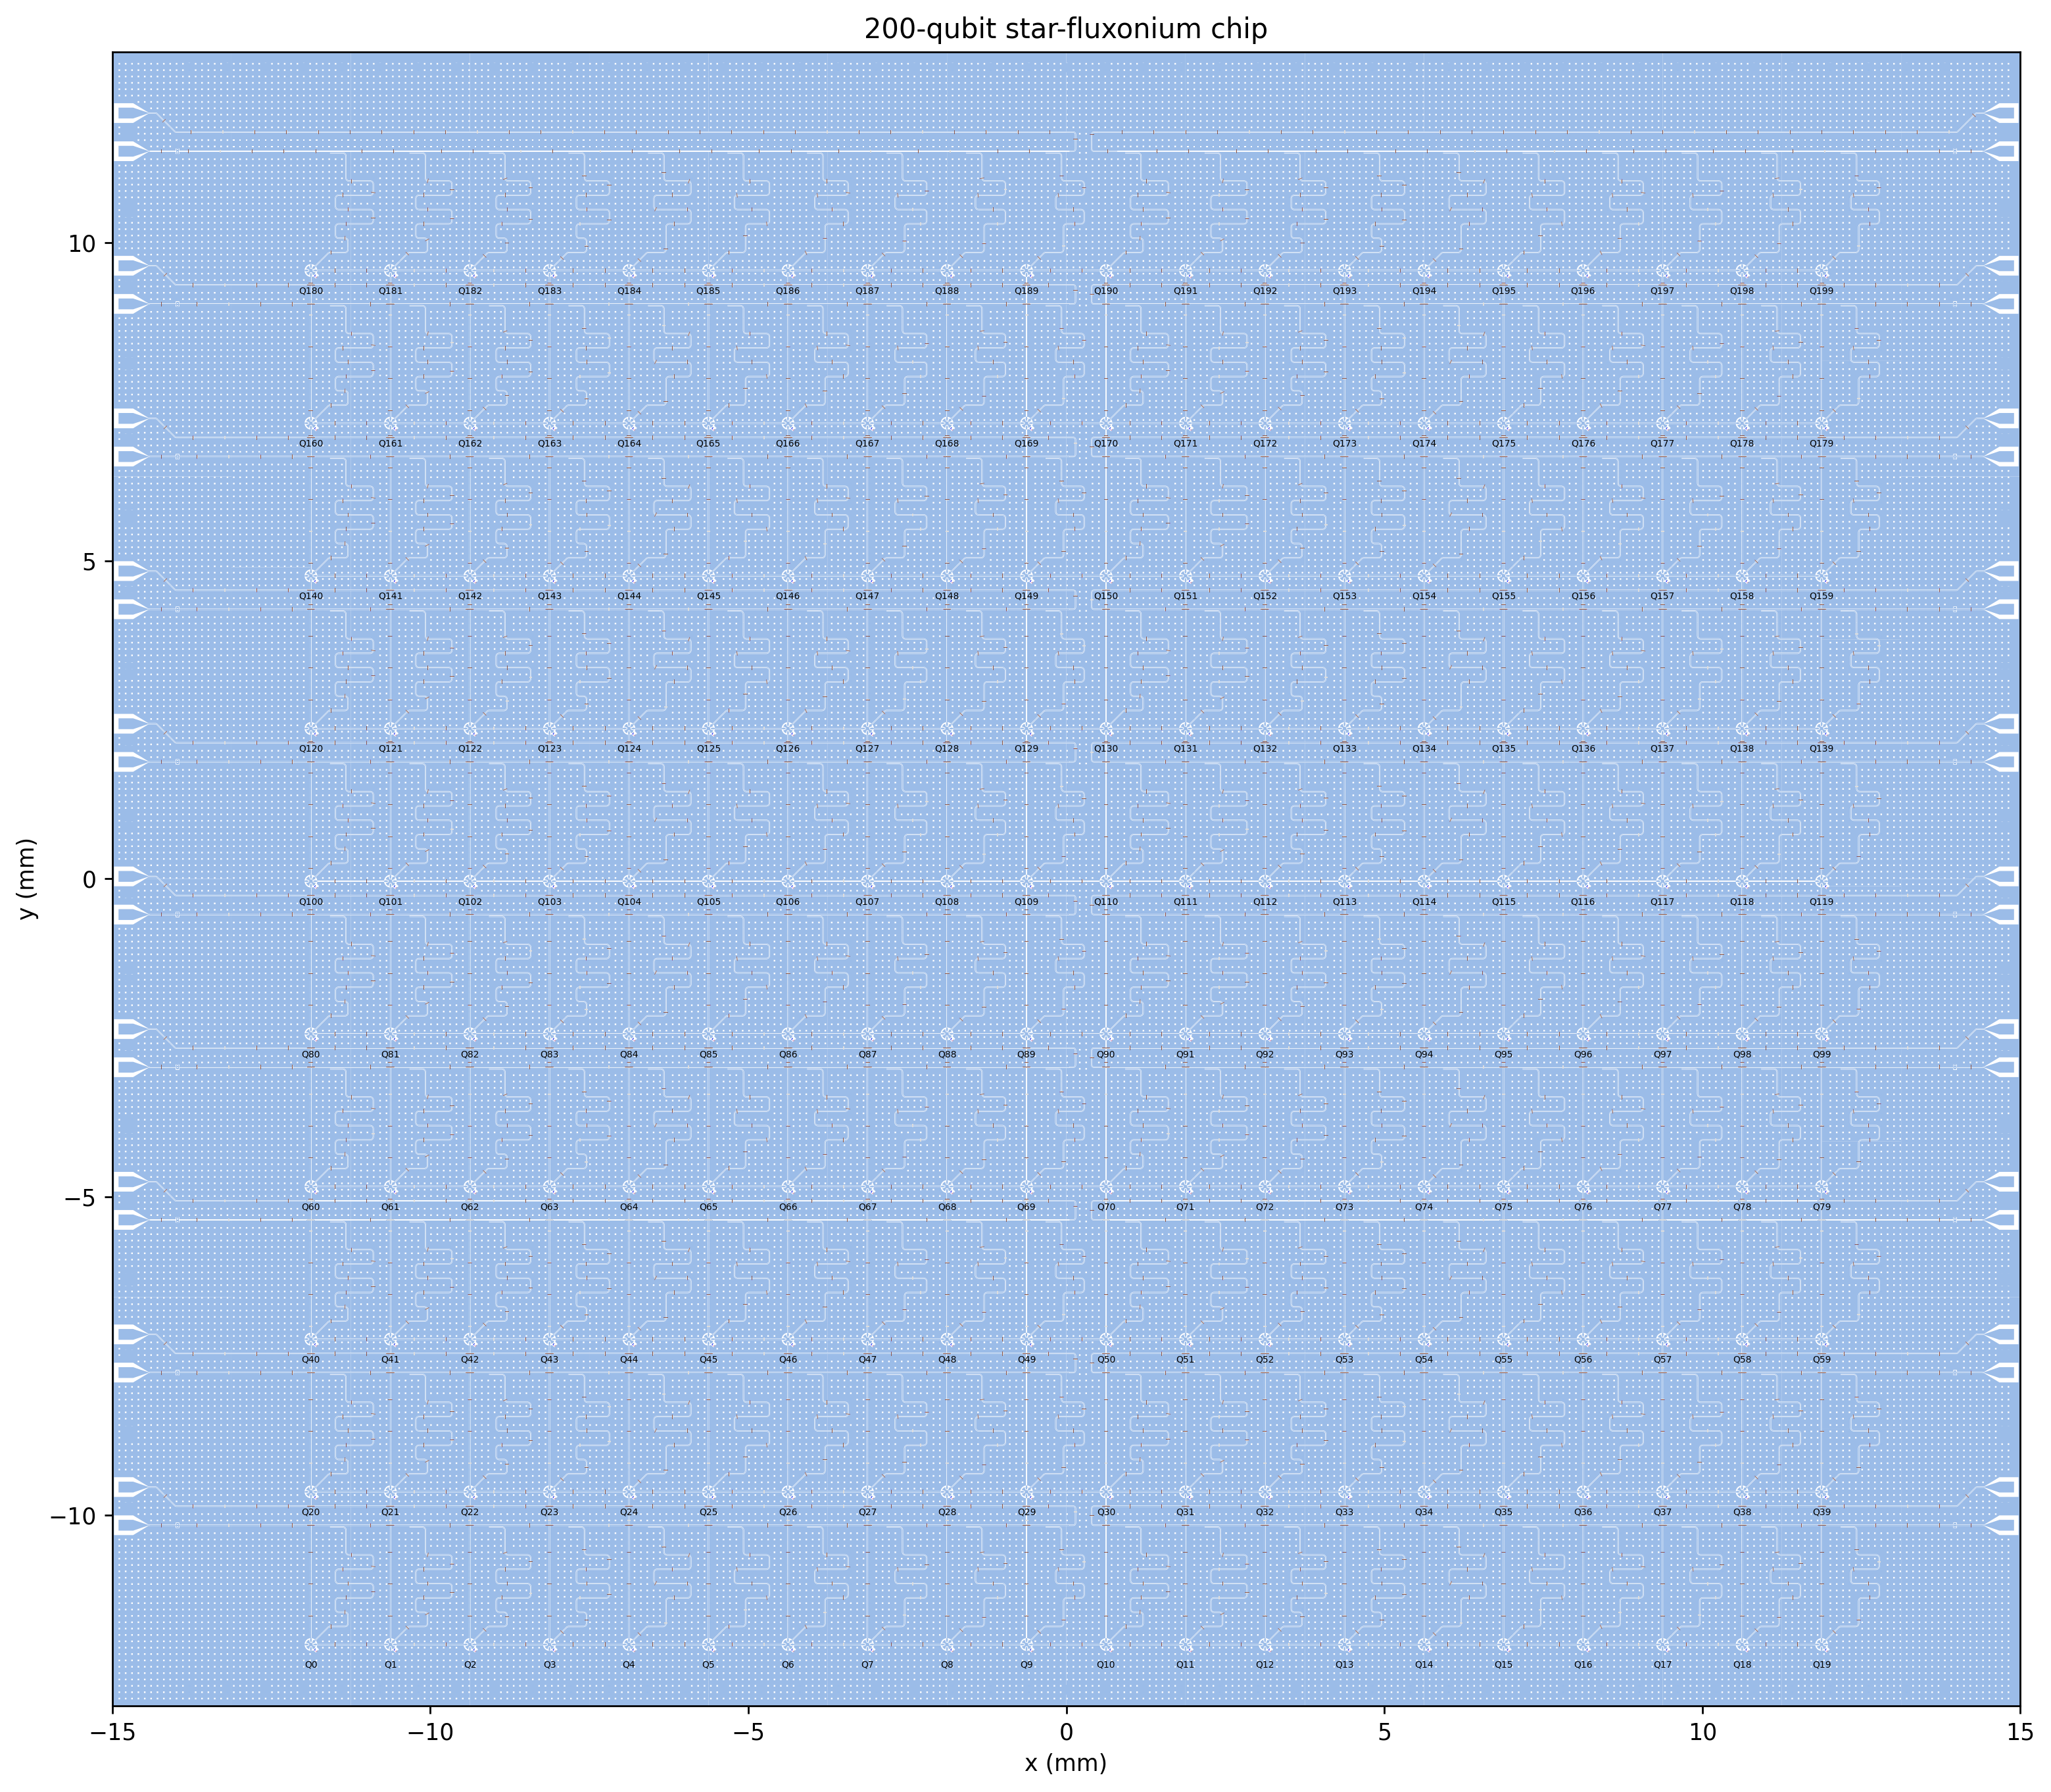

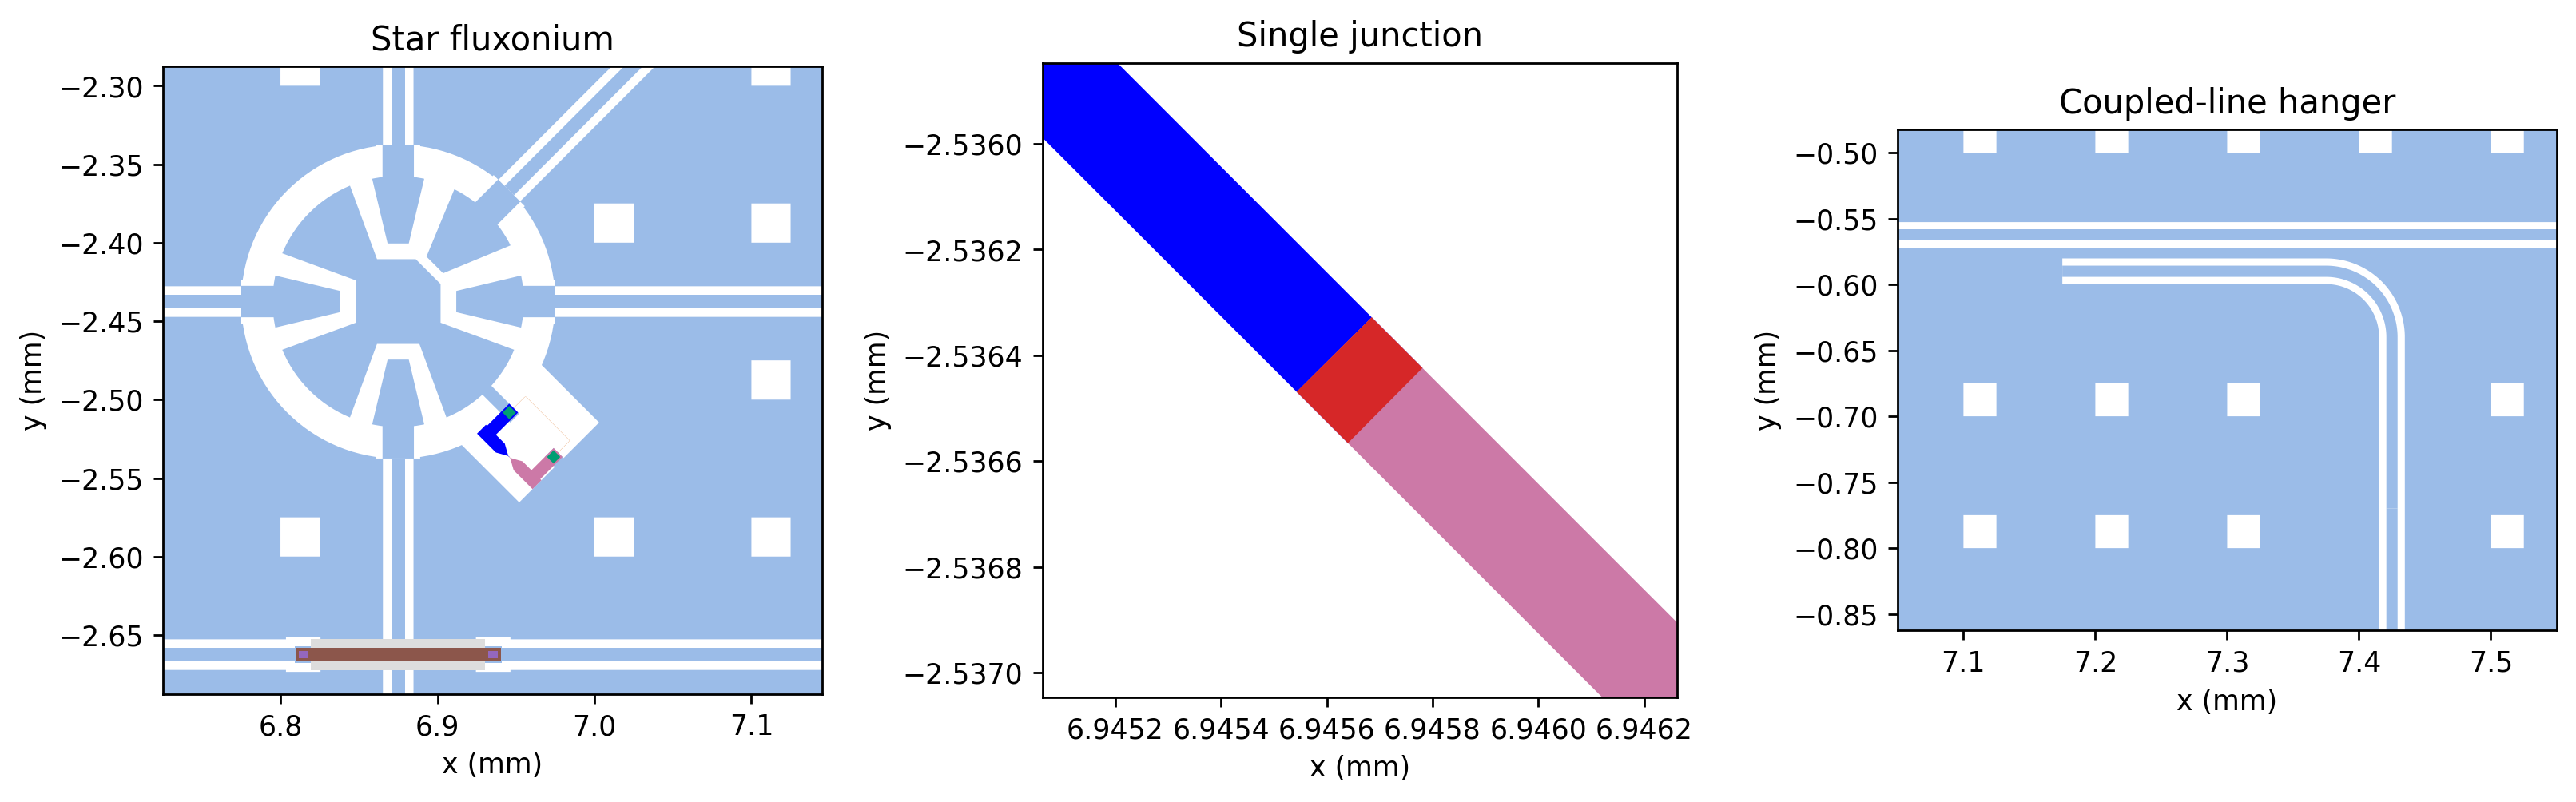

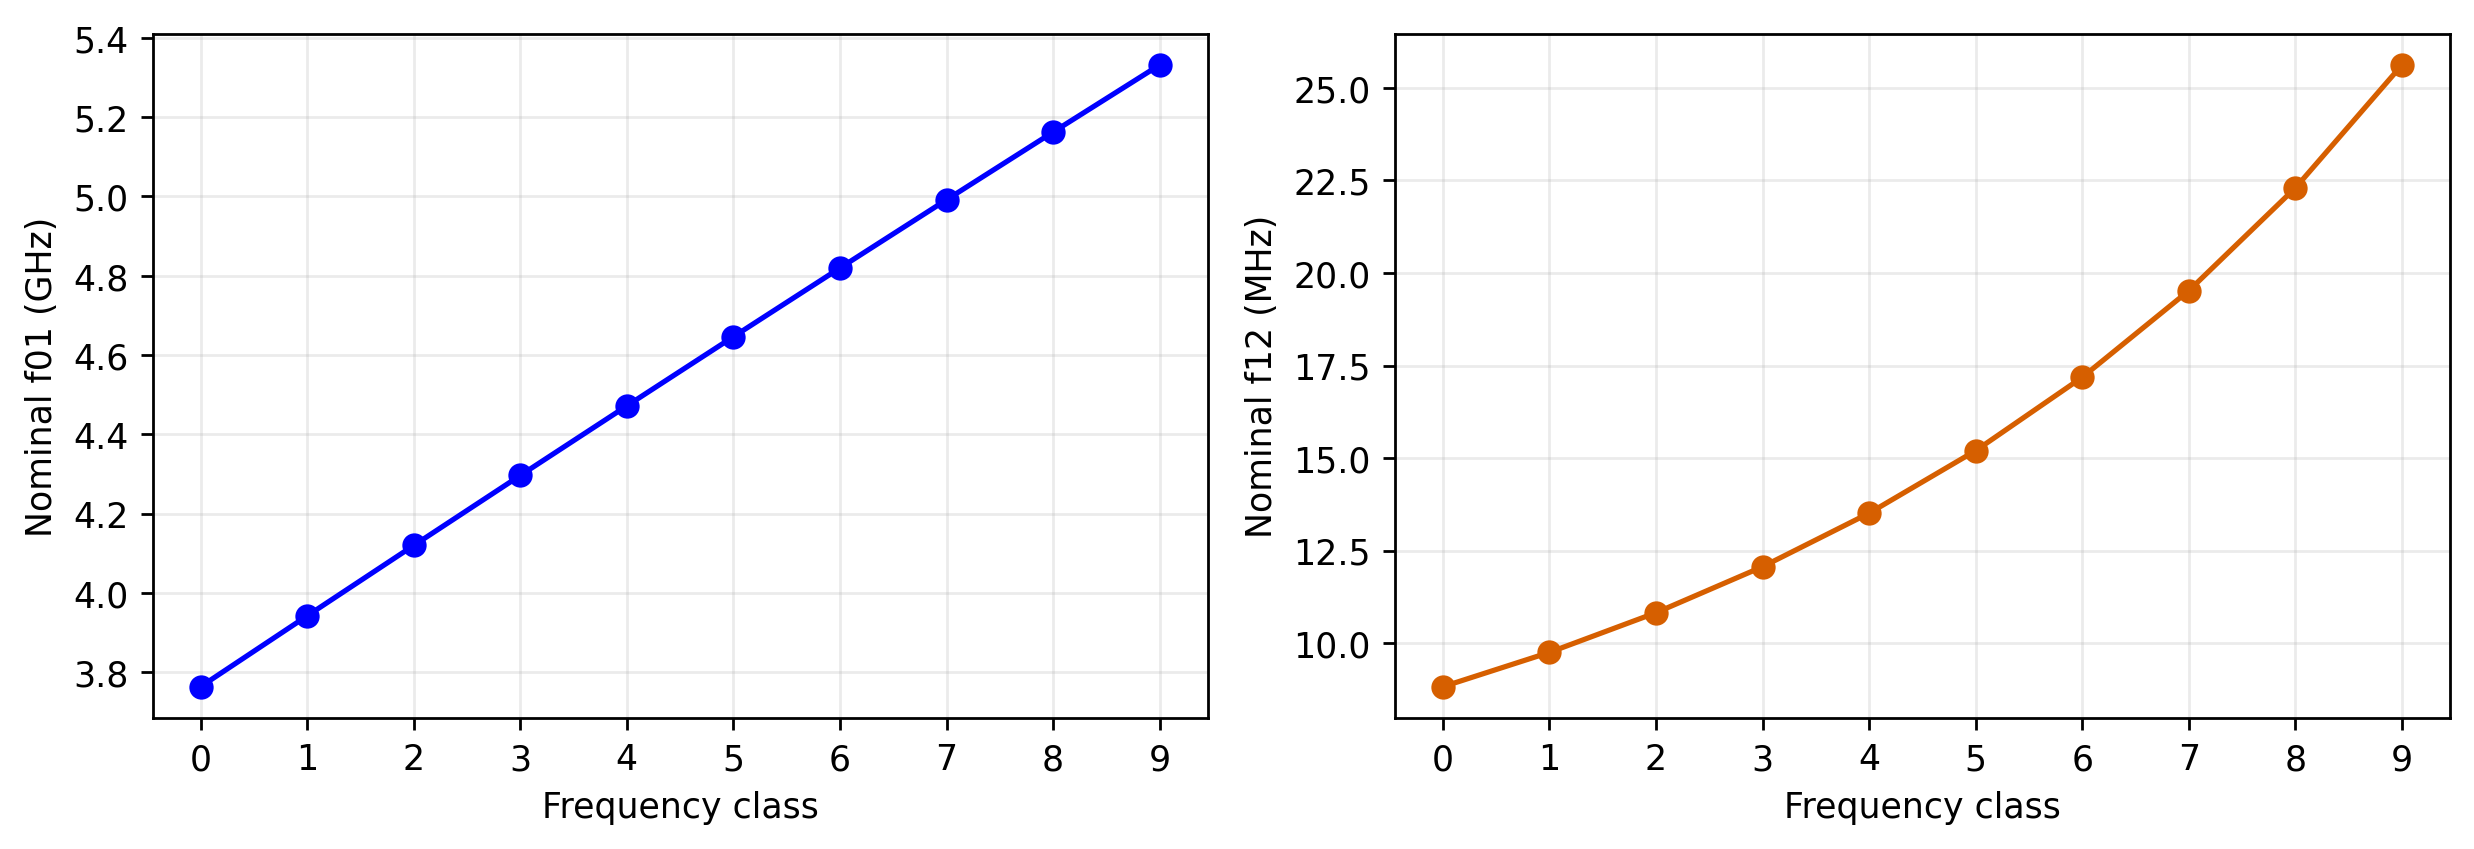

In [14]:
# --- In-Memory GDS Preview ---
colors = {
    1: "#9bbce8",
    2: "#d65f00",
    3: "#0000ff",
    4: "#cc79a7",
    5: "#009e73",
    6: "#d62728",
    7: "#dddddd",
    8: "#8c564b",
    9: "#9467bd",
}
fig, ax = plt.subplots(figsize=(14, 11), dpi=250)
for layer, color in colors.items():
    ax.add_collection(
        PolyCollection(
            [p.points for p in exported_polygons if p.layer == layer],
            facecolor=color,
            edgecolor="none",
            rasterized=True,
        )
    )
for q in qubits:
    ax.text(
        float(q.p.pos_x),
        float(q.p.pos_y) - 0.25,
        q.name,
        ha="center",
        va="top",
        fontsize=4,
        fontfamily="DejaVu Sans",
        weight="normal",
    )
ax.set(xlim=(-chip_x / 2, chip_x / 2), ylim=(-chip_y / 2, chip_y / 2), aspect="equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_title("200-qubit star-fluxonium chip", fontfamily="DejaVu Sans", weight="normal")
fig.tight_layout()
plt.show()

# --- Fluxonium, Junction, and Coupler Details ---
q = qubits[95]
qx, qy = float(q.p.pos_x), float(q.p.pos_y)
table = q.qgeometry_table("poly")
overlap = table[table.layer == 6].geometry.union_all()
jx, jy = overlap.centroid.x, overlap.centroid.y
tee = couplers[95]
tx, ty = float(tee.p.pos_x), float(tee.p.pos_y)
views = [
    ((qx - 0.15, qx + 0.27), (qy - 0.25, qy + 0.15), "Star fluxonium"),
    ((jx - 0.0006, jx + 0.0006), (jy - 0.0006, jy + 0.0006), "Single junction"),
    ((tx - 0.25, tx + 0.25), (ty - 0.30, ty + 0.08), "Coupled-line hanger"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=250)
for ax, (xlim, ylim, title) in zip(axes, views):
    for layer, color in colors.items():
        ax.add_collection(
            PolyCollection(
                [p.points for p in exported_polygons if p.layer == layer],
                facecolor=color,
                edgecolor="none",
                rasterized=True,
            )
        )
    ax.set(xlim=xlim, ylim=ylim, aspect="equal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
fig.tight_layout()
plt.show()

# --- Nominal Zero-Flux Spectrum ---
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=250)
axes[0].plot(
    spectrum_table.frequency_class, spectrum_table.f01_GHz, "o-", color="#0000ff"
)
axes[0].set_ylabel("Nominal f01 (GHz)", fontfamily="DejaVu Sans", weight="normal")
axes[1].plot(
    spectrum_table.frequency_class, spectrum_table.f12_GHz * 1000, "o-", color="#d65f00"
)
axes[1].set_ylabel("Nominal f12 (MHz)", fontfamily="DejaVu Sans", weight="normal")
for ax in axes:
    ax.set_xlabel("Frequency class", fontfamily="DejaVu Sans", weight="normal")
    ax.set_xticks(range(10))
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()